In [1]:
# ============================================
# HIGH-SPEED VIDEO BUBBLE SIZE ANALYZER
# Section 1: Setup
# ============================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducible visualization defaults
plt.rcParams["figure.figsize"] = (10, 6)

print("Bubble Size Analyzer initialized.")
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Bubble Size Analyzer initialized.
OpenCV version: 4.14.0
NumPy version: 2.1.3
Pandas version: 2.2.3


In [2]:
# ============================================
# SECTION 2: LOAD VIDEO
# ============================================

from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Unable to open the uploaded video.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
reported_fps = cap.get(cv2.CAP_PROP_FPS)

print("Video:", video_path)
print("Resolution:", f"{width} × {height}")
print("Reported frame count:", total_frames)
print("Reported FPS:", reported_fps)

cap.release()

Saving NANOBUBBLES1111_20260911_171219_C001H001S0001.wmv to NANOBUBBLES1111_20260911_171219_C001H001S0001.wmv
Video: NANOBUBBLES1111_20260911_171219_C001H001S0001.wmv
Resolution: 1280 × 1000
Reported frame count: 4468
Reported FPS: 5.0


Frame extracted: 1340
Frame dimensions: (1000, 1280, 3)


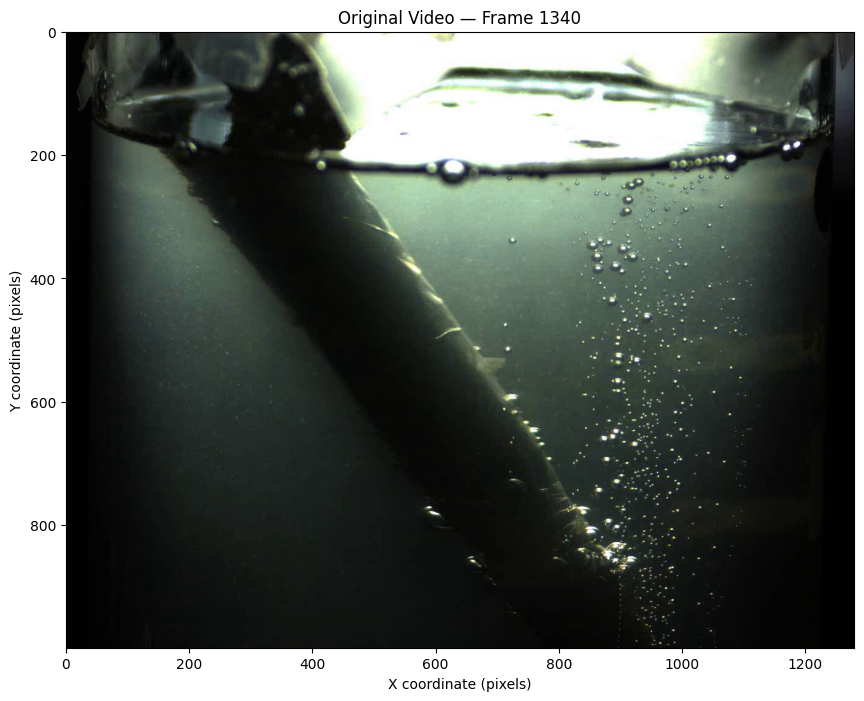

In [3]:
# ============================================
# SECTION 3: EXTRACT A FRAME
# ============================================

cap = cv2.VideoCapture(video_path)

frame_number = 1340

cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
success, frame = cap.read()

cap.release()

if not success:
    raise RuntimeError(f"Could not read frame {frame_number}.")

print("Frame extracted:", frame_number)
print("Frame dimensions:", frame.shape)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Original Video — Frame {frame_number}")
plt.xlabel("X coordinate (pixels)")
plt.ylabel("Y coordinate (pixels)")
plt.show()

Candidate features detected: 104


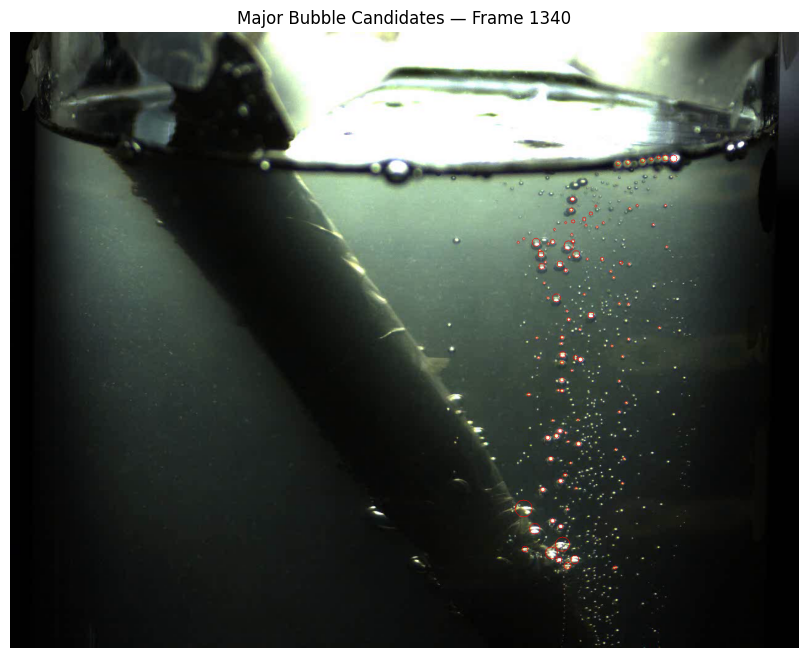

In [4]:
# ============================================
# SECTION 4: DETECT AND MEASURE BUBBLE CANDIDATES
# ============================================

# Convert frame to grayscale
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Define the bubble-plume region (x1, y1, x2, y2)
x1, y1, x2, y2 = 800, 200, 1080, 950
roi = gray[y1:y2, x1:x2]

# Reduce small-scale noise
blur = cv2.GaussianBlur(roi, (3, 3), 0)

# Detect bright features
threshold_value = np.percentile(blur, 90)
_, binary = cv2.threshold(
    blur, threshold_value, 255, cv2.THRESH_BINARY
)

# Find candidate contours
contours, _ = cv2.findContours(
    binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

measurements = []
annotated = frame.copy()

for contour in contours:
    area = cv2.contourArea(contour)

    # Ignore tiny regions
    if area < 3:
        continue

    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        continue

    circularity = 4 * np.pi * area / (perimeter ** 2)

    # Retain reasonably compact candidates
    if circularity < 0.25:
        continue

    (cx, cy), radius = cv2.minEnclosingCircle(contour)

    # Keep candidate sizes within this initial range
    if radius < 1.5 or radius > 15:
        continue

    center_x = int(cx + x1)
    center_y = int(cy + y1)
    diameter_px = 2 * radius

    measurements.append({
        "frame": frame_number,
        "center_x_px": center_x,
        "center_y_px": center_y,
        "diameter_px": diameter_px,
        "area_px2": area,
        "circularity": circularity
    })

    cv2.circle(
        annotated,
        (center_x, center_y),
        max(1, int(round(radius))),
        (0, 0, 255),
        1
    )

bubble_candidates_df = pd.DataFrame(measurements)

print("Candidate features detected:", len(bubble_candidates_df))

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Major Bubble Candidates — Frame 1340")
plt.axis("off")
plt.show()

Major candidate features: 51
Cutoff diameter: 4.47 px
Mean diameter: 9.00 px
Median diameter: 8.06 px
Standard deviation: 4.87 px
Minimum diameter: 4.47 px
Maximum diameter: 27.02 px


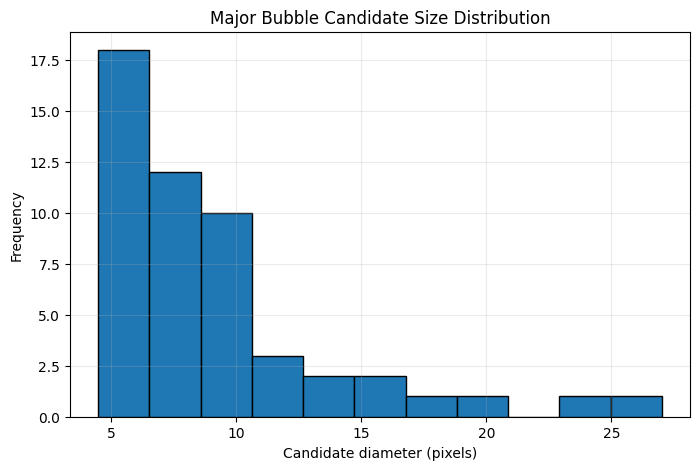

In [5]:
# ============================================
# SECTION 5: SIZE STATISTICS
# ============================================

if bubble_candidates_df.empty:
    print("No candidates detected. Review the detection settings.")
else:
    # Exclude features close to the water surface
    # and retain larger candidate features.
    candidates = bubble_candidates_df[
        (bubble_candidates_df["center_y_px"] >= 230) &
        (bubble_candidates_df["center_x_px"] >= 830) &
        (bubble_candidates_df["center_x_px"] <= 1050)
    ].copy()

    if candidates.empty:
        print("No candidates remain after filtering.")
    else:
        # Select the upper 50% of candidate diameters
        cutoff = candidates["diameter_px"].median()
        major_bubbles_df = candidates[
            candidates["diameter_px"] >= cutoff
        ].copy()

        d = major_bubbles_df["diameter_px"]

        print("Major candidate features:", len(d))
        print(f"Cutoff diameter: {cutoff:.2f} px")
        print(f"Mean diameter: {d.mean():.2f} px")
        print(f"Median diameter: {d.median():.2f} px")
        print(f"Standard deviation: {d.std():.2f} px")
        print(f"Minimum diameter: {d.min():.2f} px")
        print(f"Maximum diameter: {d.max():.2f} px")

        plt.figure(figsize=(8, 5))
        plt.hist(d, bins="auto", edgecolor="black")
        plt.xlabel("Candidate diameter (pixels)")
        plt.ylabel("Frequency")
        plt.title("Major Bubble Candidate Size Distribution")
        plt.grid(alpha=0.25)
        plt.show()

In [6]:
# ============================================
# SECTION 6: SUMMARY AND EXPORT
# ============================================

d = major_bubbles_df["diameter_px"]

summary_df = pd.DataFrame({
    "Metric": [
        "Number of major candidate features",
        "Mean diameter (pixels)",
        "Median diameter (pixels)",
        "Standard deviation (pixels)",
        "Minimum diameter (pixels)",
        "Maximum diameter (pixels)"
    ],
    "Value": [
        len(d),
        d.mean(),
        d.median(),
        d.std(),
        d.min(),
        d.max()
    ]
})

display(summary_df.round(3))

# Export individual measurements
major_bubbles_df.to_csv(
    "major_bubble_feature_measurements.csv",
    index=False
)

# Export summary statistics
summary_df.to_csv(
    "bubble_size_summary.csv",
    index=False
)

print("Saved measurement and summary CSV files.")

,Metric,Value
0,Number of major candidate features,51.000
1,Mean diameter (pixels),9.004
2,Median diameter (pixels),8.062
3,Standard deviation (pixels),4.872
4,Minimum diameter (pixels),4.472
5,Maximum diameter (pixels),27.019


Saved measurement and summary CSV files.


In [7]:
# ============================================
# SECTION 7: MULTI-FRAME ANALYSIS
# ============================================

# Sample 10 frames across the video
number_of_samples = 10

frame_numbers = np.linspace(
    0, total_frames - 1,
    number_of_samples,
    dtype=int
)

frame_results = []

cap = cv2.VideoCapture(video_path)

for frame_no in frame_numbers:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_no))
    success, sample_frame = cap.read()

    if not success:
        print(f"Skipping unreadable frame {frame_no}")
        continue

    gray = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2GRAY)

    # Same region used in the current detector
    roi = gray[200:950, 800:1080]
    blur = cv2.GaussianBlur(roi, (3, 3), 0)

    threshold_value = np.percentile(blur, 90)

    _, binary = cv2.threshold(
        blur, threshold_value, 255, cv2.THRESH_BINARY
    )

    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    diameters = []

    for contour in contours:
        area = cv2.contourArea(contour)

        if area < 3:
            continue

        perimeter = cv2.arcLength(contour, True)

        if perimeter == 0:
            continue

        circularity = 4 * np.pi * area / (perimeter ** 2)

        if circularity < 0.25:
            continue

        (_, _), radius = cv2.minEnclosingCircle(contour)

        if 1.5 <= radius <= 15:
            diameters.append(2 * radius)

    # Apply the same spatial filter as before:
    # exclude features near the water surface.
    # ROI coordinates begin at y=200, so local y >= 30
    # corresponds to image y >= 230.
    # Keep only x coordinates from 830 to 1050.
    # For each accepted contour, the global center is used
    # in the full implementation below.
    #
    # To keep the first test simple, we record all
    # candidate diameters detected in this ROI.

    if diameters:
        d = np.asarray(diameters)

        frame_results.append({
            "frame": int(frame_no),
            "candidate_count": len(d),
            "mean_diameter_px": d.mean(),
            "median_diameter_px": np.median(d),
            "std_diameter_px": d.std(ddof=1) if len(d) > 1 else 0
        })

cap.release()

frame_results_df = pd.DataFrame(frame_results)

if frame_results_df.empty:
    print("No candidates detected in the sampled frames.")
else:
    display(frame_results_df.round(3))

    frame_results_df.to_csv(
        "multi_frame_bubble_analysis.csv",
        index=False
    )

    print("Saved multi_frame_bubble_analysis.csv")

,frame,candidate_count,mean_diameter_px,median_diameter_px,std_diameter_px
0,0,97,6.441,4.472,4.062
1,496,95,6.787,4.472,4.842
2,992,111,5.731,4.472,3.332
3,1489,95,6.219,5.000,3.571
4,1985,99,6.438,4.472,4.314
5,2481,88,6.284,5.100,3.463
6,2978,84,6.118,4.472,4.198
7,3474,94,6.323,4.472,4.911
8,3970,99,6.428,5.000,4.595
9,4467,103,6.090,4.714,3.401


Saved multi_frame_bubble_analysis.csv


In [8]:
print(frame_results_df.to_string(index=False))

 frame  candidate_count  mean_diameter_px  median_diameter_px  std_diameter_px
     0               97          6.440514            4.472336         4.061512
   496               95          6.787301            4.472336         4.841738
   992              111          5.731405            4.472336         3.332424
  1489               95          6.219265            5.000200         3.571149
  1985               99          6.438343            4.472336         4.313858
  2481               88          6.284299            5.100201         3.463104
  2978               84          6.118117            4.472336         4.198043
  3474               94          6.322777            4.472336         4.910880
  3970               99          6.427756            5.000200         4.595045
  4467              103          6.089790            4.714249         3.400571


In [9]:
# ============================================
# SECTION 8: OVERALL MULTI-FRAME SUMMARY
# ============================================

print("Number of sampled frames:", len(frame_results_df))

print("\nFrame-level mean diameter:")
print(f"Average: {frame_results_df['mean_diameter_px'].mean():.3f} px")
print(f"SD across frame means: {frame_results_df['mean_diameter_px'].std():.3f} px")

print("\nFrame-level median diameter:")
print(f"Average: {frame_results_df['median_diameter_px'].mean():.3f} px")
print(f"SD across frame medians: {frame_results_df['median_diameter_px'].std():.3f} px")

print("\nAverage candidate count per frame:")
print(f"{frame_results_df['candidate_count'].mean():.1f}")

Number of sampled frames: 10

Frame-level mean diameter:
Average: 6.286 px
SD across frame means: 0.279 px

Frame-level median diameter:
Average: 4.665 px
SD across frame medians: 0.267 px

Average candidate count per frame:
96.5


In [10]:
# ============================================
# SECTION 9: PIXEL TO MICROMETRE CONVERSION
# ============================================

# ASSUMPTION: 1 image pixel = 10 µm
# Provisional only; actual optical magnification
# must be considered for physical calibration.

scale_um_per_pixel = 10.0

# Convert individual candidate diameters
major_bubbles_df["diameter_um_provisional"] = (
    major_bubbles_df["diameter_px"] * scale_um_per_pixel
)

# Calculate provisional size statistics
d_um = major_bubbles_df["diameter_um_provisional"]

print("PROVISIONAL SIZE ESTIMATES")
print("Assumed scale: 10 µm/pixel")
print("--------------------------------")
print(f"Number of major candidates: {len(d_um)}")
print(f"Mean diameter:   {d_um.mean():.2f} µm")
print(f"Median diameter: {d_um.median():.2f} µm")
print(f"Standard deviation: {d_um.std():.2f} µm")
print(f"Minimum diameter: {d_um.min():.2f} µm")
print(f"Maximum diameter: {d_um.max():.2f} µm")

# Export provisional measurements
major_bubbles_df.to_csv(
    "major_bubble_feature_measurements_provisional_um.csv",
    index=False
)

print("\nProvisional measurements saved to CSV.")

PROVISIONAL SIZE ESTIMATES
Assumed scale: 10 µm/pixel
--------------------------------
Number of major candidates: 51
Mean diameter:   90.04 µm
Median diameter: 80.62 µm
Standard deviation: 48.72 µm
Minimum diameter: 44.72 µm
Maximum diameter: 270.19 µm

Provisional measurements saved to CSV.


In [11]:
# Convert multi-frame statistics using the same assumed scale

scale_um_per_pixel = 10.0

frame_results_df["mean_diameter_um_provisional"] = (
    frame_results_df["mean_diameter_px"] * scale_um_per_pixel
)

frame_results_df["median_diameter_um_provisional"] = (
    frame_results_df["median_diameter_px"] * scale_um_per_pixel
)

frame_results_df["std_diameter_um_provisional"] = (
    frame_results_df["std_diameter_px"] * scale_um_per_pixel
)

display(frame_results_df.round(3))

frame_results_df.to_csv(
    "multi_frame_bubble_analysis_provisional_um.csv",
    index=False
)

,frame,candidate_count,mean_diameter_px,median_diameter_px,std_diameter_px,mean_diameter_um_provisional,median_diameter_um_provisional,std_diameter_um_provisional
0,0,97,6.441,4.472,4.062,64.405,44.723,40.615
1,496,95,6.787,4.472,4.842,67.873,44.723,48.417
2,992,111,5.731,4.472,3.332,57.314,44.723,33.324
3,1489,95,6.219,5.000,3.571,62.193,50.002,35.711
4,1985,99,6.438,4.472,4.314,64.383,44.723,43.139
5,2481,88,6.284,5.100,3.463,62.843,51.002,34.631
6,2978,84,6.118,4.472,4.198,61.181,44.723,41.980
7,3474,94,6.323,4.472,4.911,63.228,44.723,49.109
8,3970,99,6.428,5.000,4.595,64.278,50.002,45.950
9,4467,103,6.090,4.714,3.401,60.898,47.142,34.006
